# Zonasi Seismik dan Statistik Hazard

Notebook ini mendokumentasikan langkah `python -m gempa.zoning` (modul `src/gempa/zoning.py` dan `stats.py`).
Label K-Means lama (Low–Very High dari magnitudo & kedalaman) hanya mengelompokkan karakteristik gempa, bukan wilayah.
Di sini K-Means dipakai untuk tujuan yang lebih tepat: **membagi wilayah menjadi zona sumber gempa**, lalu menghitung
statistik Gutenberg–Richter tiap zona.

1. **Data:** katalog bersih (`data_cleaning.ipynb`): gempa utama, Mw ≥ Mc tahunan, lolos verifikasi USGS.
2. **Lapisan kedalaman:** dangkal (< 70 km), menengah (70–300 km), dalam (> 300 km). Sumber dangkal (sesar & megathrust)
   dan zona Benioff yang lebih dalam punya karakter berbeda, sehingga di-cluster terpisah.
3. **K-Means per lapisan** pada koordinat Kartesius 3D (km). k dipilih sebagai jumlah zona terbanyak yang setiap zonanya
   masih berisi ≥ 200 event, agar b-value tiap zona stabil.
4. **Pembanding HDBSCAN** (clustering berbasis kepadatan).
5. **Statistik hazard per zona:** Mc, b-value, laju tahunan, periode ulang, probabilitas Poisson.

**Referensi**
- Gutenberg, B. & Richter, C. F. (1944). Frequency of earthquakes in California. *BSSA*, 34(4), 185–188.
- Aki, K. (1965). Maximum likelihood estimate of b in the formula log N = a − bM and its confidence limits. *Bull. Earthq. Res. Inst.*, 43, 237–239.
- Shi, Y. & Bolt, B. A. (1982). The standard error of the magnitude-frequency b value. *BSSA*, 72(5), 1677–1687.
- Campello, R. J. G. B., Moulavi, D. & Sander, J. (2013). Density-based clustering based on hierarchical density estimates. *PAKDD 2013*, LNCS 7819, 160–172.
- Pusgen (2017). *Peta Sumber dan Bahaya Gempa Indonesia Tahun 2017*.

In [1]:
import sys
from pathlib import Path

import folium
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import poisson
from sklearn.cluster import HDBSCAN

sys.path.insert(0, str(Path.cwd().parent / "src"))

from gempa import paths
from gempa.stats import annual_rate
from gempa.zoning import (DEPTH_LAYERS, HDBSCAN_PARAMS, MIN_ZONE_EVENTS, build_geojson, load_clean_catalog, run,
                          to_ecef_km, zone_polygons)

clean = load_clean_catalog()
result, mc_by_year, mc_floor = run(clean)
events, zones = result.events, result.zones
polygons = zone_polygons(events)

saved = pd.read_csv(paths.ZONE_STATS)
assert list(saved["zone_id"]) == list(zones["zone_id"]), "artifact models/ berbeda, jalankan python -m gempa.zoning"
print(f"Katalog bersih: {len(clean):,} event -> event zonasi: {len(events):,}")
print(f"Mc keseluruhan (batas bawah Mc zona): {mc_floor:.1f}")

Katalog bersih: 131,131 event -> event zonasi: 25,773
Mc keseluruhan (batas bawah Mc zona): 3.6


## 1. Data dan Lapisan Kedalaman

,event,mw_maks,kedalaman_median
layer,,,
dangkal,17968,7.90,13.0
menengah,6336,7.89,131.0
dalam,1469,7.11,464.0


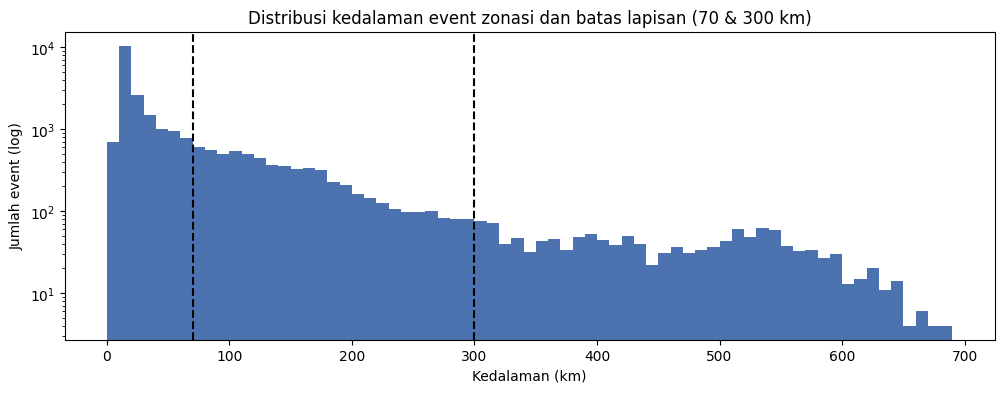

In [2]:
layer_names = {code: name for code, name, _ in DEPTH_LAYERS}
display(events.groupby("layer").agg(event=("mw", "size"), mw_maks=("mw", "max"), kedalaman_median=("depth", "median"))
        .reindex([c for c, _, _ in DEPTH_LAYERS]).rename(index=layer_names).round(2))

fig, ax = plt.subplots(figsize=(12, 4))
ax.hist(events["depth"], bins=np.arange(0, 700, 10), color="#4C72B0")
for _, _, upper in DEPTH_LAYERS[:-1]:
    ax.axvline(upper, color="k", ls="--")
ax.set_yscale("log")
ax.set_xlabel("Kedalaman (km)")
ax.set_ylabel("Jumlah event (log)")
ax.set_title("Distribusi kedalaman event zonasi dan batas lapisan (70 & 300 km)")
plt.show()

## 2. Memilih Jumlah Zona (k)

Silhouette mengukur seberapa terpisah klaster. Pada sebaran gempa yang menerus sepanjang busur subduksi, silhouette
terus turun ketika k bertambah, sehingga selalu memilih k kecil (beberapa zona raksasa) yang tidak berguna untuk zonasi.
Kriteria yang dipakai: **k terbesar yang zona terkecilnya masih ≥ 200 event**. Dengan 200 event, galat b-value
(Shi & Bolt) sekitar ±0,07.

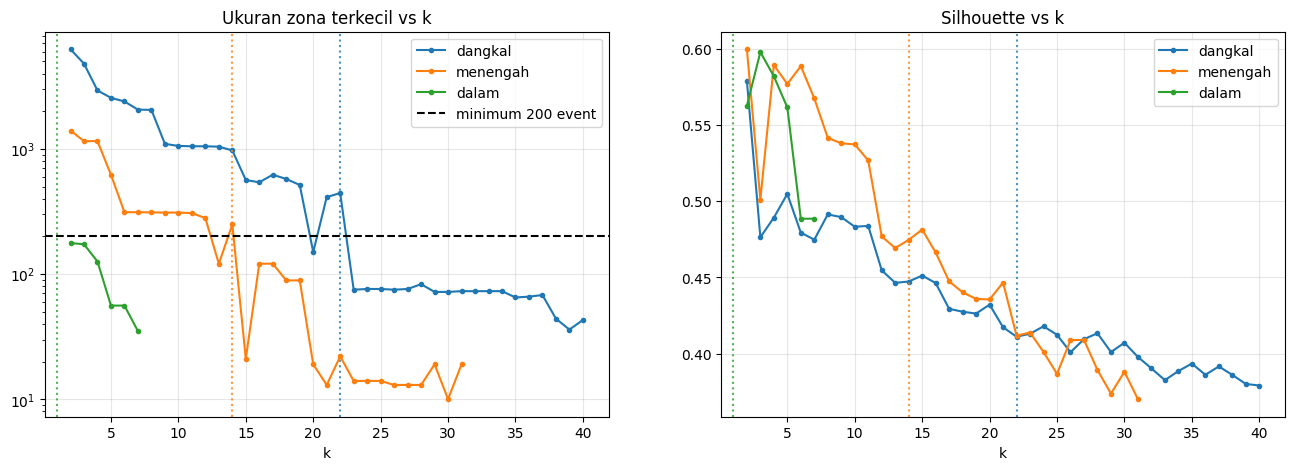

k terpilih: {'dangkal': 22, 'menengah': 14, 'dalam': 1}


In [3]:
k_chosen = {code: len(m["zone_ids"]) for code, m in result.models.items()}
scan = result.scan
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for code, group in scan.groupby("layer", sort=False):
    axes[0].plot(group["k"], group["min_size"], marker="o", ms=3, label=layer_names[code])
    axes[1].plot(group["k"], group["silhouette"], marker="o", ms=3, label=layer_names[code])
    for ax in axes:
        ax.axvline(k_chosen[code], color=ax.lines[-1].get_color(), ls=":", alpha=0.8)
axes[0].axhline(MIN_ZONE_EVENTS, color="k", ls="--", label=f"minimum {MIN_ZONE_EVENTS} event")
axes[0].set_yscale("log")
axes[0].set_title("Ukuran zona terkecil vs k")
axes[1].set_title("Silhouette vs k")
for ax in axes:
    ax.set_xlabel("k")
    ax.legend()
    ax.grid(alpha=0.3)
plt.show()
print("k terpilih:", {layer_names[c]: k for c, k in k_chosen.items()})

## 3. Peta Zona

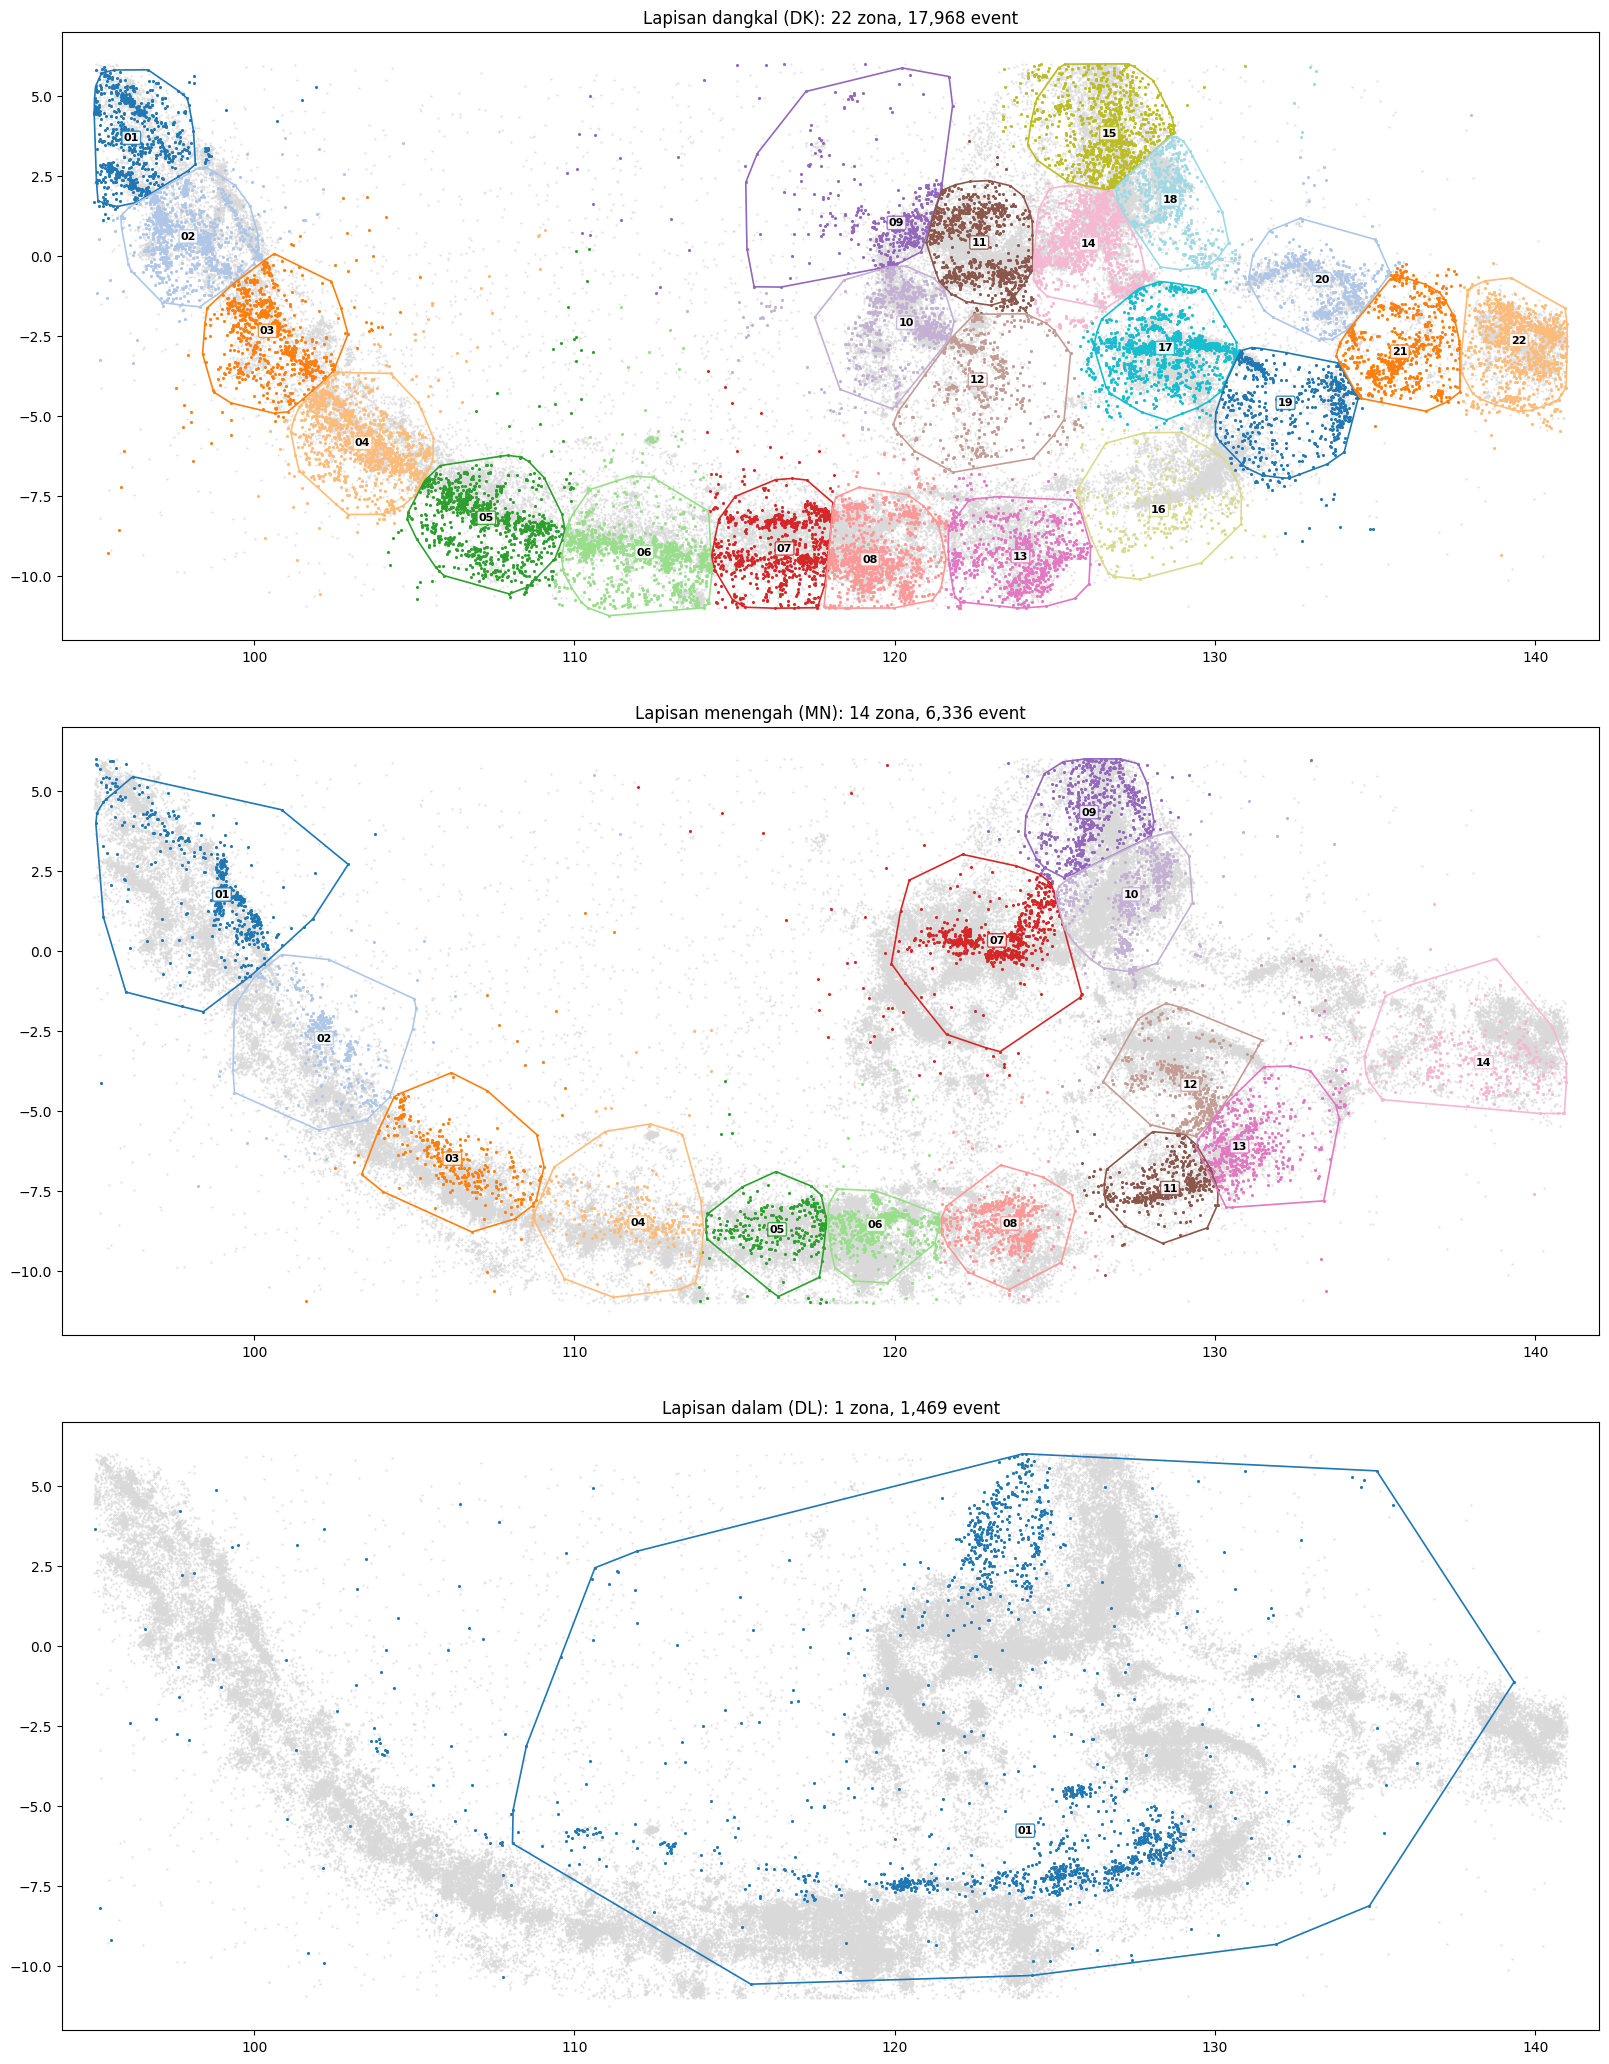

In [4]:
# tab20 tanpa abu-abu (indeks 14-15) agar tidak tertelan titik latar
palette = [plt.get_cmap("tab20")(i) for i in range(20) if i not in (14, 15)]

def draw_zones(ax, layer_events, title):
    ax.scatter(clean["longitude"], clean["latitude"], s=0.2, color="0.85", rasterized=True)
    for i, (zone_id, group) in enumerate(layer_events.groupby("zone_id")):
        color = palette[i % len(palette)]
        ax.scatter(group["longitude"], group["latitude"], s=1.5, color=color, rasterized=True)
        if zone_id in polygons:
            ring = np.array(polygons[zone_id])
            ax.plot(ring[:, 0], ring[:, 1], color=color, lw=1.2)
        ax.text(group["longitude"].median(), group["latitude"].median(), zone_id.split("-")[1],
                fontsize=8, weight="bold", ha="center", va="center",
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec=color, alpha=0.85))
    ax.set_xlim(94, 142)
    ax.set_ylim(-12, 7)
    ax.set_aspect("equal")
    ax.set_title(title)

fig, axes = plt.subplots(3, 1, figsize=(16, 21))
for ax, (code, name, _) in zip(axes, DEPTH_LAYERS):
    layer_events = events[events["layer"] == code]
    draw_zones(ax, layer_events, f"Lapisan {name} ({code}): {k_chosen[code]} zona, {len(layer_events):,} event")
plt.tight_layout()
plt.show()

## 4. K-Means vs HDBSCAN

HDBSCAN mencari daerah padat dan menandai sisanya sebagai *noise*, sehingga cocok untuk menemukan klaster dengan bentuk
bebas. Untuk zonasi, setiap titik wilayah perlu masuk ke satu zona, jadi K-Means (partisi lengkap) dipakai sebagai model
utama dan HDBSCAN sebagai pembanding. ARI dihitung hanya pada event yang bukan noise HDBSCAN.

,n_events,kmeans_k,kmeans_silhouette,kmeans_davies_bouldin,hdbscan_clusters,hdbscan_noise,hdbscan_silhouette,hdbscan_davies_bouldin,ari_on_hdbscan_core
layer,,,,,,,,,
dangkal,17968,22,0.429,0.753,15,0.219,0.207,0.735,0.160
menengah,6336,14,0.475,0.712,7,0.119,0.603,0.437,0.449
dalam,1469,1,NaN,NaN,2,0.124,0.574,0.631,0.000


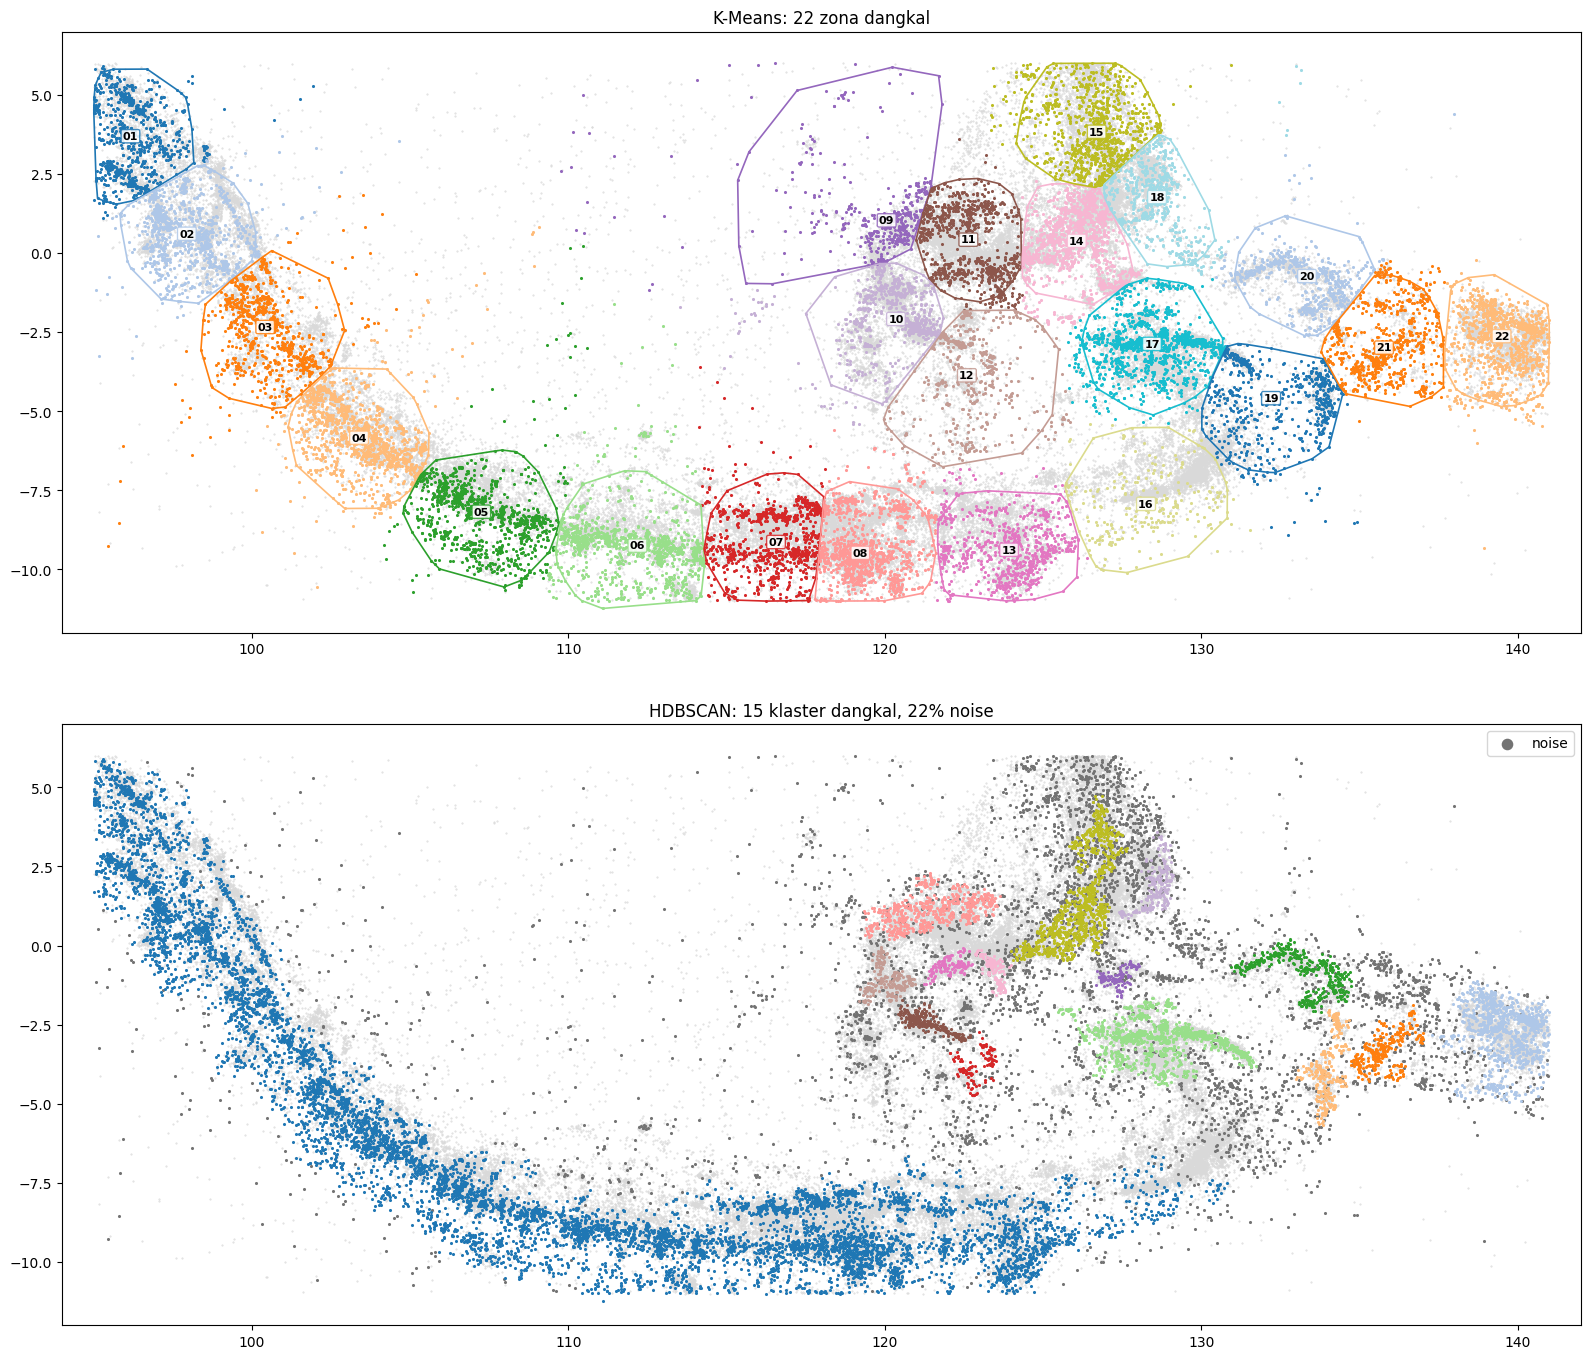

In [5]:
display(result.comparison.set_index("layer").rename(index=layer_names).round(3))

dk = events[events["layer"] == "DK"]
hd = HDBSCAN(copy=True, **HDBSCAN_PARAMS).fit(to_ecef_km(dk["latitude"], dk["longitude"], dk["depth"]))
fig, axes = plt.subplots(2, 1, figsize=(16, 14))
draw_zones(axes[0], dk, f"K-Means: {k_chosen['DK']} zona dangkal")
axes[1].scatter(clean["longitude"], clean["latitude"], s=0.2, color="0.85", rasterized=True)
noise = hd.labels_ < 0
axes[1].scatter(dk.loc[noise, "longitude"], dk.loc[noise, "latitude"], s=1.5, color="0.45", label="noise", rasterized=True)
for label in range(hd.labels_.max() + 1):
    sel = hd.labels_ == label
    axes[1].scatter(dk.loc[sel, "longitude"], dk.loc[sel, "latitude"], s=1.5, color=palette[label % len(palette)], rasterized=True)
axes[1].set_xlim(94, 142)
axes[1].set_ylim(-12, 7)
axes[1].set_aspect("equal")
axes[1].legend(markerscale=6)
axes[1].set_title(f"HDBSCAN: {hd.labels_.max() + 1} klaster dangkal, {noise.mean():.0%} noise")
plt.tight_layout()
plt.show()

## 5. Penampang Kedalaman

Penampang memperlihatkan zona Benioff: lempeng yang menunjam membuat gempa makin dalam ke arah utara di bawah Jawa–Nusa
Tenggara dan ke arah barat/timur di Laut Maluku. Lapisan kedalaman memisahkan sumber dangkal dari bagian lempeng yang menunjam.

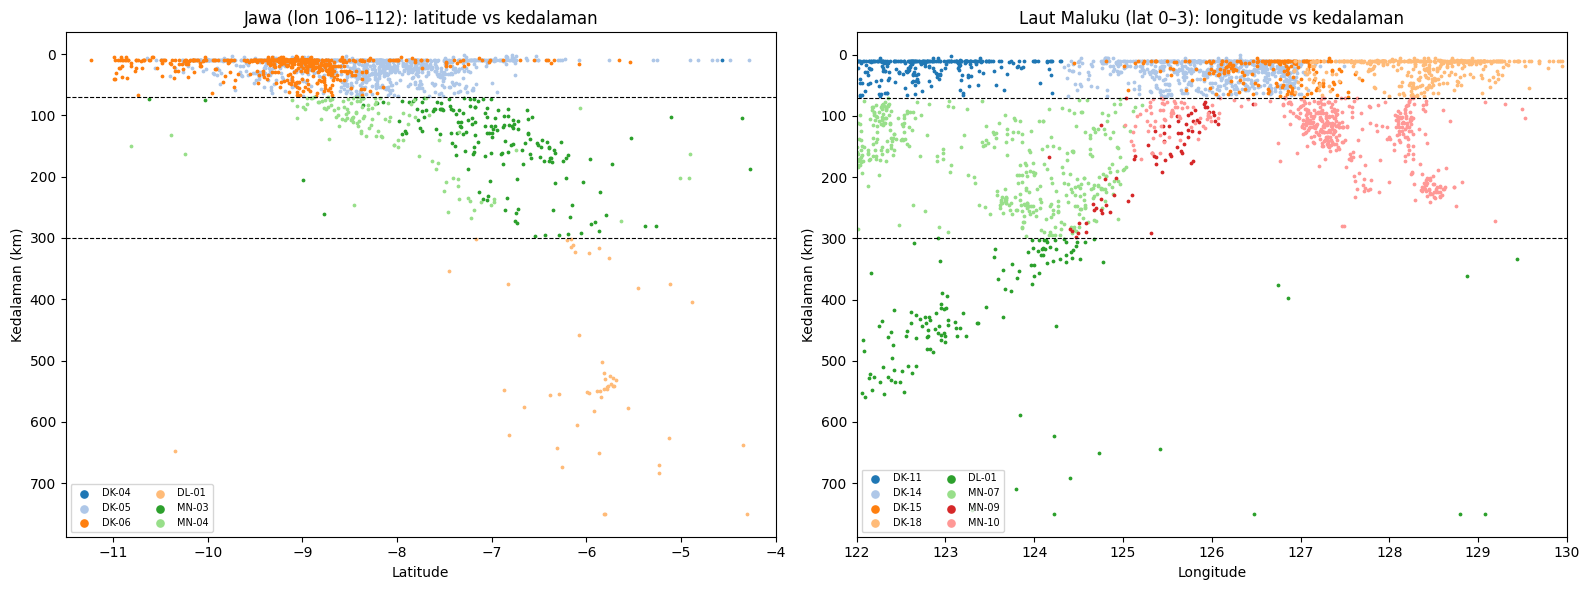

In [6]:
sections = [
    ("Jawa (lon 106–112): latitude vs kedalaman", events["longitude"].between(106, 112), "latitude", (-11.5, -4)),
    ("Laut Maluku (lat 0–3): longitude vs kedalaman", events["latitude"].between(0, 3), "longitude", (122, 130)),
]
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, (title, sel, axis, lim) in zip(axes, sections):
    part = events[sel & events[axis].between(*lim)]
    for i, (zone_id, group) in enumerate(part.groupby("zone_id")):
        ax.scatter(group[axis], group["depth"], s=3, color=palette[i % len(palette)], label=zone_id)
    for _, _, upper in DEPTH_LAYERS[:-1]:
        ax.axhline(upper, color="k", ls="--", lw=0.8)
    ax.set_xlim(*lim)
    ax.invert_yaxis()
    ax.set_xlabel(axis.capitalize())
    ax.set_ylabel("Kedalaman (km)")
    ax.set_title(title)
    ax.legend(fontsize=7, markerscale=3, ncol=2)
plt.tight_layout()
plt.show()

## 6. Statistik Gutenberg–Richter per Zona

- **Mc zona** = maximum curvature + 0,2 pada event zona, minimal Mc keseluruhan katalog.
- **b-value** dari maximum likelihood Aki (1965) dengan galat Shi & Bolt (1982), hanya memakai tahun yang katalognya
  sudah lengkap pada Mc zona. Bila event ≥ Mc zona kurang dari 50, dipakai b-value lapisannya.
- **Laju tahunan** N(≥M) = laju(≥Mc) · 10^(−b(M − Mc)), periode ulang = 1/laju, dan probabilitas minimal satu kejadian
  dalam T tahun = 1 − exp(−laju · T) (model Poisson; valid karena gempa susulan sudah dibuang).

In [7]:
table = zones[["zone_id", "name", "n_events", "mw_max", "mc", "b", "b_sigma", "b_source",
               "return_period_m5", "return_period_m6", "p10_m6", "p50_m6"]]
display(table.round({"mw_max": 2, "mc": 1, "b": 2, "b_sigma": 2, "return_period_m5": 2, "return_period_m6": 1,
                     "p10_m6": 2, "p50_m6": 2}))
print(f"b-value: {zones['b'].min():.2f}–{zones['b'].max():.2f} (median {zones['b'].median():.2f})")

,zone_id,name,n_events,mw_max,mc,b,b_sigma,b_source,return_period_m5,return_period_m6,p10_m6,p50_m6
0,DK-01,"Northern Sumatra, Indonesia (dangkal) #1",803,7.73,4.0,0.92,0.04,zona,0.33,2.7,0.97,1.00
1,DK-02,"Northern Sumatra, Indonesia (dangkal) #2",943,7.04,4.2,1.00,0.05,zona,0.29,2.9,0.97,1.00
2,DK-03,"Southern Sumatra, Indonesia (dangkal) #1",819,7.13,4.2,0.93,0.05,zona,0.28,2.4,0.99,1.00
3,DK-04,"Southern Sumatra, Indonesia (dangkal) #2",1169,6.86,4.1,0.93,0.03,zona,0.18,1.5,1.00,1.00
4,DK-05,"Java, Indonesia (dangkal)",1119,6.75,4.2,1.11,0.04,zona,0.27,3.5,0.94,1.00
5,DK-06,"South of Java, Indonesia (dangkal)",1137,6.48,3.9,1.00,0.04,zona,0.29,2.8,0.97,1.00
6,DK-07,"Sumbawa Region, Indonesia (dangkal)",911,5.91,4.0,1.14,0.05,zona,0.52,7.2,0.75,1.00
7,DK-08,"Sumba Region, Indonesia (dangkal)",1078,6.72,4.1,1.25,0.06,zona,0.54,9.6,0.65,0.99
8,DK-09,"Minahassa Peninsula, Sulawesi (dangkal) #1",439,7.52,4.0,1.00,0.07,zona,0.74,7.3,0.75,1.00
9,DK-10,"Sulawesi, Indonesia (dangkal) #1",692,6.63,4.1,1.02,0.06,zona,0.54,5.7,0.83,1.00


b-value: 0.85–1.42 (median 1.10)


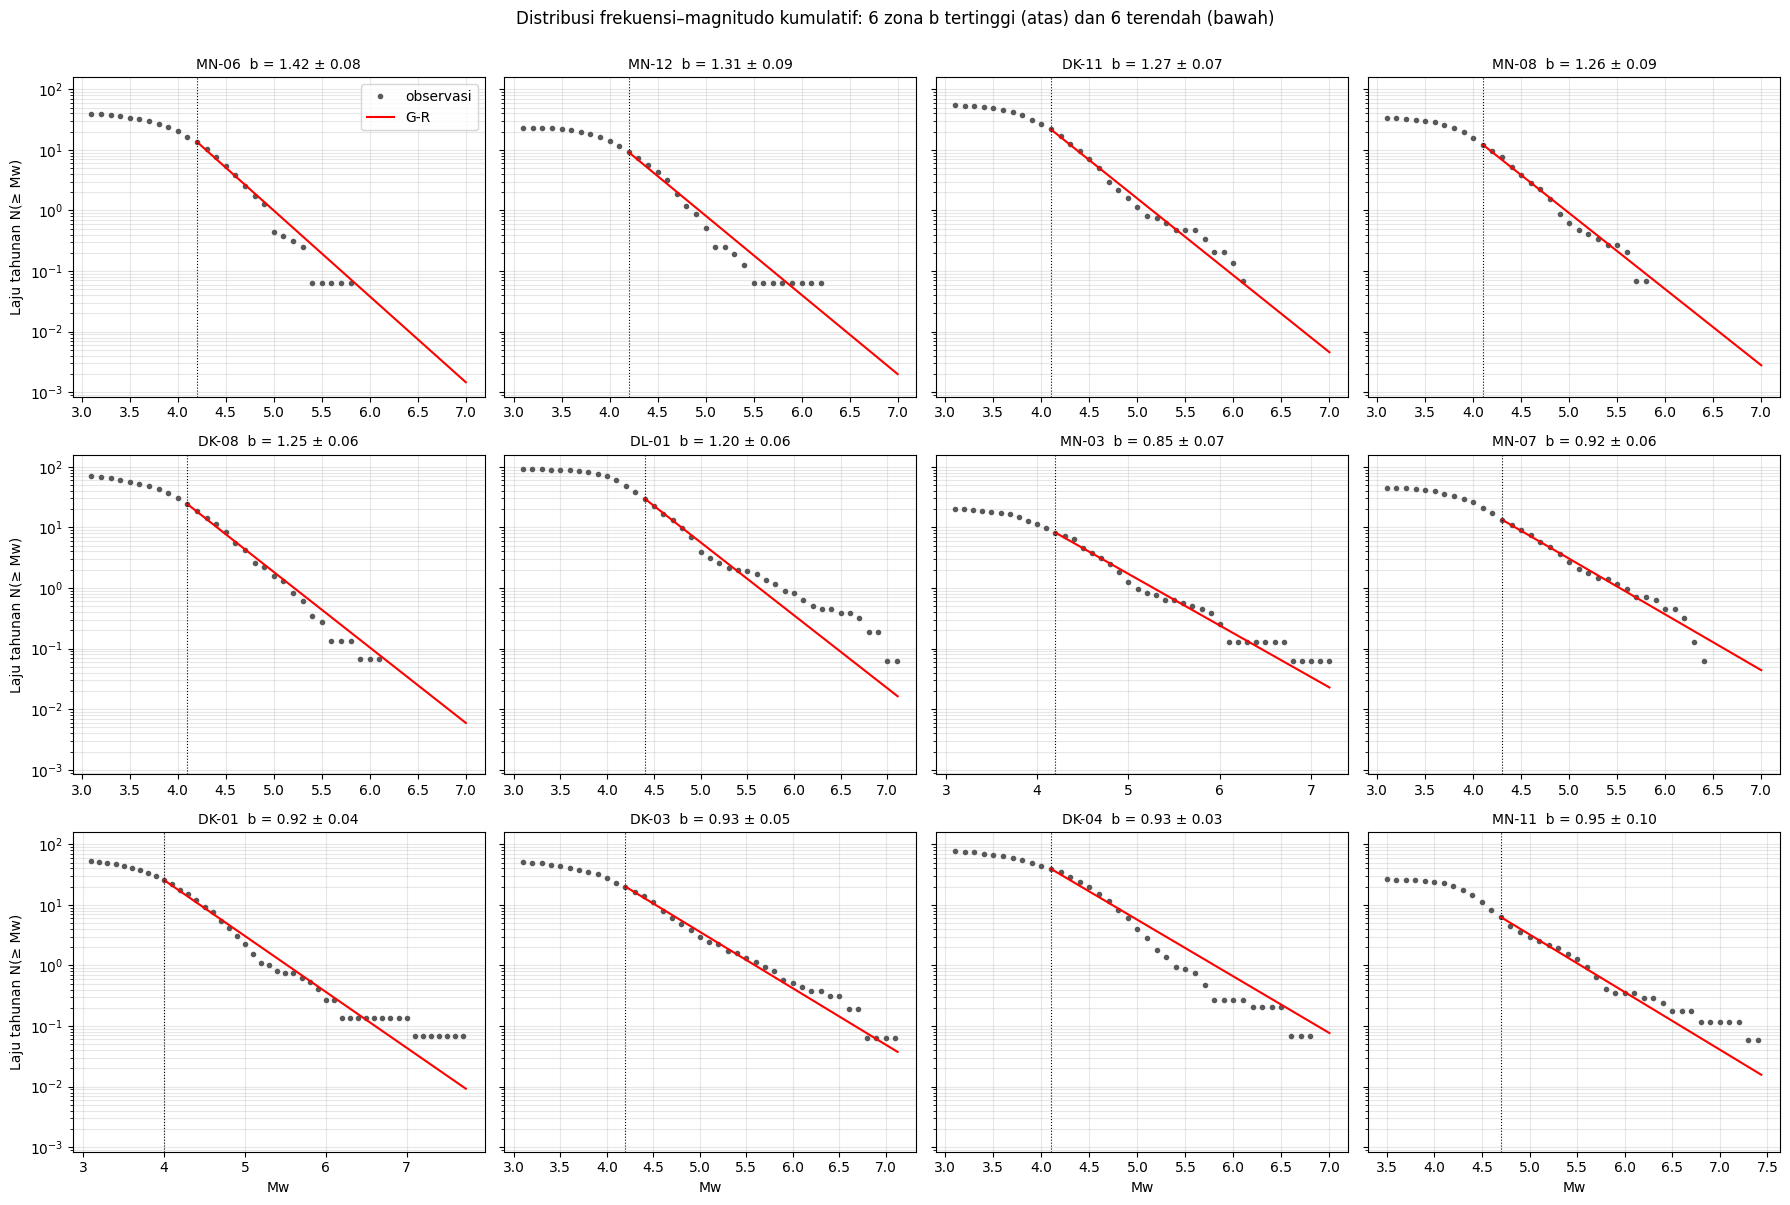

In [8]:
def gr_plot(ax, zone_id):
    z = zones.set_index("zone_id").loc[zone_id]
    ev = events[events["zone_id"] == zone_id]
    years_ok = [year for year, value in mc_by_year.items() if value <= z["mc"] + 1e-9]
    m = ev.loc[ev["time"].dt.year.isin(years_ok), "mw"].to_numpy()
    grid = np.arange(np.floor(m.min() * 10) / 10, m.max() + 0.05, 0.1)
    rate = np.array([(m >= g).sum() for g in grid]) / z["exposure_years"]
    ax.semilogy(grid, rate, "o", ms=3, color="0.35", label="observasi")
    mm = np.linspace(z["mc"], max(m.max(), 7.0), 50)
    ax.semilogy(mm, annual_rate(z["n_b"] / z["exposure_years"], z["b"], z["mc"], mm), "r-", label="G-R")
    ax.axvline(z["mc"], color="k", ls=":", lw=0.8)
    ax.set_title(f"{zone_id}  b = {z['b']:.2f} ± {z['b_sigma']:.2f}", fontsize=10)
    ax.grid(alpha=0.3, which="both")

picks = list(zones.nlargest(6, "b")["zone_id"]) + list(zones.nsmallest(6, "b")["zone_id"])
fig, axes = plt.subplots(3, 4, figsize=(18, 12), sharey=True)
for ax, zone_id in zip(axes.flat, picks):
    gr_plot(ax, zone_id)
for ax in axes[-1]:
    ax.set_xlabel("Mw")
for ax in axes[:, 0]:
    ax.set_ylabel("Laju tahunan N(≥ Mw)")
axes[0, 0].legend()
fig.suptitle("Distribusi frekuensi–magnitudo kumulatif: 6 zona b tertinggi (atas) dan 6 terendah (bawah)", y=1.0)
plt.tight_layout()
plt.show()

## 7. Observasi vs Prediksi

Uji konsistensi: berapa gempa utama M ≥ 5 dan M ≥ 6 yang tercatat selama periode katalog dibandingkan dengan yang
diprediksi relasi Gutenberg–Richter tiap zona. Garis abu-abu menunjukkan interval 95% Poisson di sekitar nilai prediksi.
Untuk M ≥ 6 relasi diekstrapolasi dari Mc (±4), sehingga uji ini juga menguji ekstrapolasi.

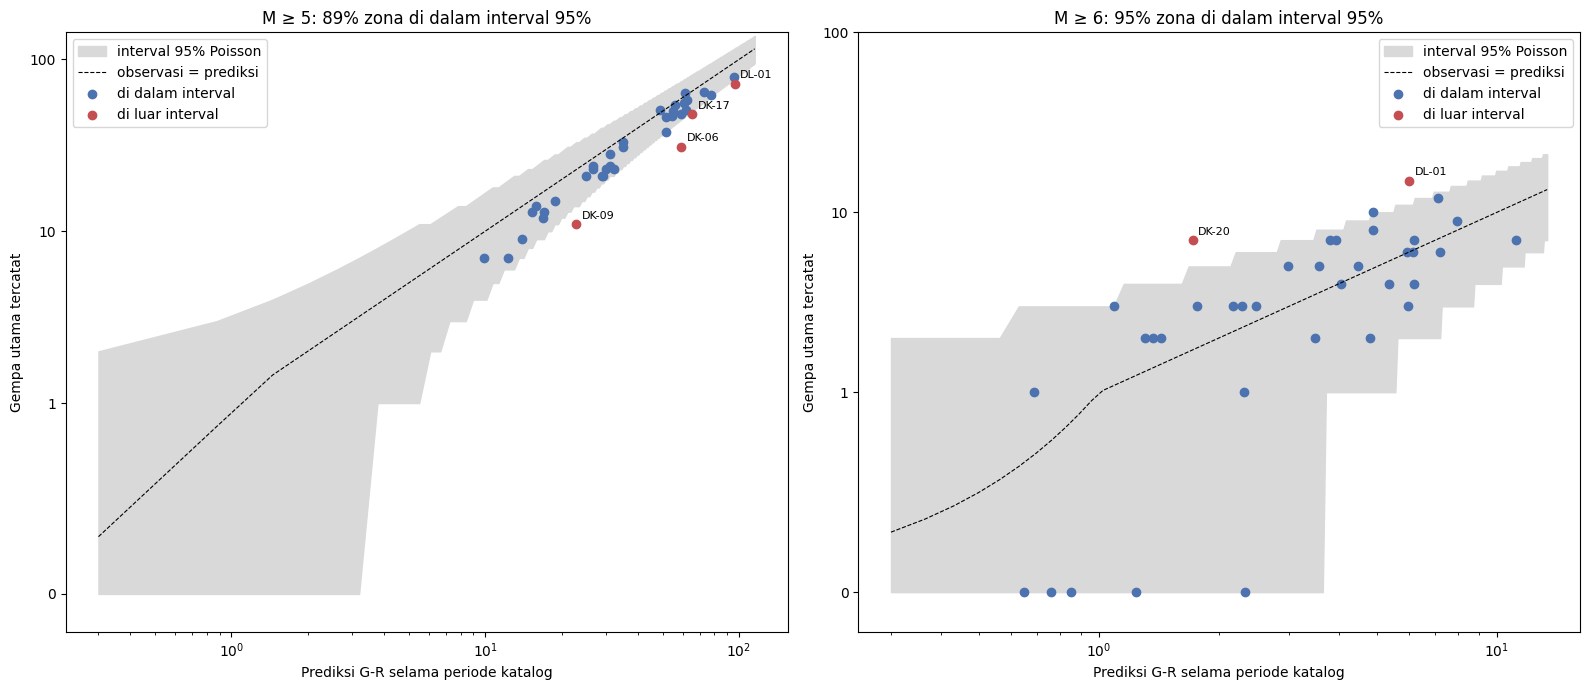

,observed_m5,expected_m5_catalog,observed_m6,expected_m6_catalog
total semua zona,1293.0,1563.4,164.0,140.6


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, m in zip(axes, ["m5", "m6"]):
    expected, observed = zones[f"expected_{m}_catalog"], zones[f"observed_{m}"]
    lo, hi = poisson.ppf(0.025, expected), poisson.ppf(0.975, expected)
    inside = (observed >= lo) & (observed <= hi)
    grid = np.linspace(0.3, expected.max() * 1.2, 200)
    ax.fill_between(grid, poisson.ppf(0.025, grid), poisson.ppf(0.975, grid), color="0.85", label="interval 95% Poisson")
    ax.plot(grid, grid, "k--", lw=0.8, label="observasi = prediksi")
    ax.scatter(expected[inside], observed[inside], color="#4C72B0", label="di dalam interval")
    ax.scatter(expected[~inside], observed[~inside], color="#C44E52", label="di luar interval")
    for _, z in zones[~inside].iterrows():
        ax.annotate(z["zone_id"], (z[f"expected_{m}_catalog"], z[f"observed_{m}"]), fontsize=8,
                    xytext=(4, 4), textcoords="offset points")
    ax.set_xscale("log")
    ax.set_yscale("symlog", linthresh=1)
    ax.set_ylim(bottom=-0.2)
    ax.set_yticks([0, 1, 10, 100], ["0", "1", "10", "100"])
    ax.set_xlabel("Prediksi G-R selama periode katalog")
    ax.set_ylabel("Gempa utama tercatat")
    ax.set_title(f"M ≥ {m[1]}: {inside.mean():.0%} zona di dalam interval 95%")
    ax.legend()
plt.tight_layout()
plt.show()

total = zones[["observed_m5", "expected_m5_catalog", "observed_m6", "expected_m6_catalog"]].sum()
display(total.round(1).to_frame("total semua zona").T)

## 8. Peta Probabilitas M ≥ 6 dalam 10 Tahun

In [10]:
geojson = build_geojson(zones, polygons)
m = folium.Map(location=[-2.5, 118], zoom_start=5, tiles="OpenStreetMap")
colors = ["#fee5d9", "#fcae91", "#fb6a4a", "#de2d26", "#a50f15"]

def style(feature):
    p = feature["properties"]["p10_m6"] or 0
    return {"fillColor": colors[min(int(p * 5), 4)], "color": "#555", "weight": 1, "fillOpacity": 0.55}

for code, name, _ in reversed(DEPTH_LAYERS):
    layer = {"type": "FeatureCollection",
             "features": [f for f in geojson["features"] if f["properties"]["layer"] == code]}
    folium.GeoJson(
        layer, name=f"Lapisan {name}", style_function=style, show=(code == "DK"),
        tooltip=folium.GeoJsonTooltip(["zone_id", "name", "b", "return_period_m6", "p10_m6", "p50_m6"],
                                      aliases=["Zona", "Nama", "b-value", "Periode ulang M6 (tahun)", "P(M≥6, 10 th)", "P(M≥6, 50 th)"],
                                      localize=True),
    ).add_to(m)
folium.LayerControl(collapsed=False).add_to(m)
m

## 9. Kesimpulan

- **37 zona sumber gempa** dari 25.773 gempa utama: 22 zona dangkal, 14 zona menengah, dan 1 zona dalam. Lapisan dalam
  hanya 1.469 event, sehingga tidak bisa dibagi tanpa melanggar batas minimum 200 event per zona.
- **K-Means lebih cocok daripada HDBSCAN untuk zonasi.** Di lapisan dangkal HDBSCAN menggabungkan seluruh busur
  Sumatra–Jawa–Nusa Tenggara (±4.000 km) menjadi satu klaster dan menandai 22% event sebagai noise (ARI dengan K-Means
  0,16). Di lapisan menengah keduanya lebih sepakat (ARI 0,45), dan HDBSCAN menghasilkan klaster yang lebih terpisah
  (silhouette 0,60 vs 0,48) tetapi tetap meninggalkan 12% event tanpa zona.
- **b-value 0,85–1,42 (median 1,10).** b rendah (lebih banyak gempa besar relatif terhadap gempa kecil) di zona dangkal
  Sumatra (0,92–0,93) dan lapisan menengah Jawa (0,85); b tinggi di lapisan menengah Flores–Banda (1,26–1,42).
- **Periode ulang M ≥ 6** berkisar dari ±1,5 tahun (Sumatra Selatan, dangkal) sampai ±26 tahun (Flores, menengah).
- **Validasi:** 89% zona (M ≥ 5) dan 95% zona (M ≥ 6) berada di dalam interval 95% Poisson. Secara total relasi G-R
  memprediksi 1.563 gempa utama M ≥ 5 (tercatat 1.293) dan 141 gempa M ≥ 6 (tercatat 164). Kurva frekuensi–magnitudo
  tidak lurus sempurna: ada defisit di sekitar Mw 5–5,5 dan ekor gempa besar yang lebih tebal (DL-01, DK-01), kemungkinan
  akibat campuran tipe magnitudo (gempa kecil dikonversi dari M/MLv, gempa besar dari Mw(mB)).

**Keterbatasan**
- Zona K-Means berbentuk cembung dan tidak mengikuti geometri sesar; ukurannya mengikuti kepadatan data (zona di daerah
  aktif lebih kecil).
- Pemilihan k memakai aturan ukuran minimum; hasil scan tidak selalu monoton (di lapisan dangkal k = 20 gagal, tetapi
  k = 21–22 lolos).
- Probabilitas berasal dari katalog 17 tahun dengan model Poisson, tanpa pergerakan tanah maupun kondisi tanah setempat.
  Ini **bukan** pengganti Peta Sumber dan Bahaya Gempa Indonesia (PuSGeN 2017).
- Sisa event semu kecil (Mw 4,5–5, tahun 2020–2021) masih mungkin ada, lihat `data_cleaning.ipynb`.

Hasil zonasi (`models/zones.geojson`, `models/zone_stats.csv`, `data/processed/zone_events.parquet`) akan dipakai
aplikasi pada tahap berikutnya untuk menampilkan zona dan statistik hazard di sekitar lokasi pengguna.
